# Data Exploration

This notebook looks at the raw data for the Home Credit risk dataset. The goal here is just to do a simple sanity check on the datasets provided, look at missing values, and map out which features we want to build before training our models. 

The main dataset is `application_train.csv`, but we also use historical tables like `bureau.csv` and `previous_application.csv` to capture the customer's credit history where its present. 

This exploratory work will serve as the motivation to create our `src/data_engineering.py` script, which will handle data cleaning, aggregation and feature creation to be used with our models.

Presented here are short snipets outlining the main decisions taken from the main EDA, in orderd to save space and allow more time to understand the logic behind the feature creation.


In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [32]:
from data_engineering import (create_application_features, create_historical_features, build_dataset, prepare_train_test)


## Data
The application_train table is our main dataset, where each row represents one unique applicant (SK_ID_CURR).

The other tables (bureau, previous applications, and installments) are historical records. Because they contain multiple rows for the same applicant, we cannot join them directly without messing up our row counts. To fix this, we have to group these tables by SK_ID_CURR and aggregate the rows (using counts, averages, etc.) before merging them into our final training data, which is done in the data_engineering.py file.


In [8]:
folder = "home-credit-default-risk/"

application_train = pd.read_csv(folder + "application_train.csv")
bureau = pd.read_csv(folder + "bureau.csv")
previous_application = pd.read_csv(folder + "previous_application.csv")
installments = pd.read_csv(folder + "installments_payments.csv")

In [10]:
print("Train shape:", application_train.shape)
print("Bureau shape:", bureau.shape)
print("Previous Applications shape:", previous_application.shape)
print("Installments shape:", installments.shape)

Train shape: (307511, 122)
Bureau shape: (1716428, 17)
Previous Applications shape: (1670214, 37)
Installments shape: (13605401, 8)


## Initial look
The data shows a clear class imbalance, with a baseline default rate of 8.07%. As standard classification accuracy is misleading when classes are so imbalanced, we will use ranking metrics like **ROC-AUC** to evaluate our model performance instead. 

We can also track **Precision and Recall** later in our notebook to look at the business trade-off. Recall will tell us what percentage of the actual defaulters our model managed to catch, while Precision ensures we aren't being overly aggressive and accidentally rejecting too many good customers who would have paid us back.

In [13]:
# A check to see the class imbalance to see our baseline default rate
print("Default counts:")
print(application_train["TARGET"].value_counts())
print("\nDefault percentages:")
print(application_train["TARGET"].value_counts(normalize=True) * 100)


Default counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Default percentages:
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


## Missing Values and Correlation

This initial screening gives us a complete view of our features using appropriate statistical screeners: **Pearson linear correlation** for our continuous numeric columns, and **conditional default rate ranges** to scan the risk differentiation across our categorical text variables.

This initial exploration shows that many columns have massive gaps. Because of this, my data engineering script includes a simple cutoff rule to drop heavily missing columns. Of course, for a real project with more time, you would want to consider these feature by feature, but for the purpose of getting a working prototype model up and running, we will make this modeling assumption. 

The Pearson correlation check confirms that the external scores and age are our strongest initial risk indicators, which completely matches normal credit risk patterns. For the categorical text variables, our conditional default rate range scan ranks the features by their discriminatory power based on the gap between their safest and riskiest buckets. 

These checks directly motivate the exact cleaning, ratio creation, and One-Hot/Ordinal encoding choices implemented inside our `src/data_engineering.py` script.


In [22]:
# Quick check for missing values
missing_pct = application_train.isna().mean().sort_values(ascending=False) * 100
print("Percent of missing values:")
print(missing_pct.head(15))

# Check linear relationships of numeric columns with the target column using the Pearson  correlation coefficients to rank the features
numeric_cols = application_train.select_dtypes(include="number")
correlations = numeric_cols.corr()["TARGET"].drop("TARGET").sort_values(key=abs, ascending=False)
print("\nStrongest numeric Pearson correlations with the target variable:")
print(correlations.head(15))

# Check the differentiation of categorical features relative to the target column
# Calculating the conditional default probability per category and find the maximum gap
cat_gaps = {}
for col in application_train.select_dtypes(exclude="number").columns:
    group_rates = application_train.groupby(col)["TARGET"].mean()
    cat_gaps[col] = group_rates.max() - group_rates.min()

cat_results = pd.Series(cat_gaps).sort_values(ascending=False)
print("\nCategorical features ranked by conditional default rate ranges:")
print(cat_results.head(15))


Percent of missing values:
COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
FLOORSMIN_MEDI              67.848630
YEARS_BUILD_AVG             66.497784
YEARS_BUILD_MODE            66.497784
dtype: float64

Strongest numeric Pearson correlations with the target variable:
EXT_SOURCE_3                  -0.178919
EXT_SOURCE_2                  -0.160472
EXT_SOURCE_1                  -0.155317
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
RE

## Employment-duration anomaly

The raw `DAYS_EMPLOYED` data contains the number `365243` thousands of times, which does not make sense since the other rows are normal negative days. This number is an obvious placeholder for missing data. 

To fix this, our `data_engineering.py` script replaces `365243` with `NaN` so it doesn't break our scaling weights. It then multiplies the remaining negative values by `-1` and divides by `365.25` to convert them into a clean, positive `EMPLOYMENT_YEARS` feature for our models.


In [26]:
print("Top employment days values:")
print(application_train["DAYS_EMPLOYED"].value_counts().head())

df_test = application_train[["DAYS_EMPLOYED"]].copy()

df_test["EMPLOYMENT_YEARS"] = -df_test["DAYS_EMPLOYED"].replace(365243, np.nan) / 365.25
df_test = df_test.drop(columns=["DAYS_EMPLOYED"])

print("\nNew engineered feature check:")
print(df_test["EMPLOYMENT_YEARS"].describe())


Top employment days values:
DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-199         151
-230         151
Name: count, dtype: int64

New engineered feature check:
count    252137.000000
mean          6.527500
std           6.402081
min          -0.000000
25%           2.099932
50%           4.511978
75%           8.692676
max          49.040383
Name: EMPLOYMENT_YEARS, dtype: float64


## Simple Feature Engineering

The raw application data contains useful information, but some variables are easier to interpret after simple transformations. I deliberately kept feature engineering limited to a small number of intuitive variables that I could explain economically and use consistently across all three model families.

### Age and employment duration
`DAYS_BIRTH` and `DAYS_EMPLOYED` are recorded relative to the application date. I convert these into years to make them easier to interpret.

### Simple Economic Ratios
Raw credit or income values do not necessarily capture affordability on their own. I therefore created several simple ratios:
* **Credit-to-income:** requested credit relative to applicant income
* **Annuity-to-income:** scheduled annuity relative to income
* **Credit-to-annuity:** size of credit relative to scheduled annuity
* **Goods-to-credit:** financed goods value relative to credit amount
* **Income per household member:** income adjusted for household size

These are deliberately simple not to ensure maximum performance scores but rather toe show the process of feature engineering and to ensure the data is suitable and ready to be used for model creation. These feature are created in the `src/data_engineering.py` file, and below is just a simple illustration of them.


In [33]:
application_features = create_application_features(application_train)

new_features = ["AGE_YEARS",
                "EMPLOYMENT_YEARS",
                "CREDIT_INCOME_RATIO",
                "ANNUITY_INCOME_RATIO", 
                "CREDIT_ANNUITY_RATIO",
                "GOODS_CREDIT_RATIO",
                "INCOME_PER_PERSON"]

application_features[new_features].describe().T

,count,mean,std,min,25%,50%,75%,max
AGE_YEARS,307511.0,43.906900,11.947950,20.503765,33.984942,43.121150,53.886379,6.907324e+01
EMPLOYMENT_YEARS,252137.0,6.527500,6.402081,-0.000000,2.099932,4.511978,8.692676,4.904038e+01
CREDIT_INCOME_RATIO,307511.0,3.957570,2.689728,0.004808,2.018667,3.265067,5.159880,8.473684e+01
ANNUITY_INCOME_RATIO,307499.0,0.180930,0.094574,0.000224,0.114782,0.162833,0.229067,1.875965e+00
CREDIT_ANNUITY_RATIO,307499.0,21.612322,7.823823,8.036674,15.614496,20.000000,27.099985,4.530508e+01
GOODS_CREDIT_RATIO,307233.0,0.900689,0.096630,0.166667,0.834725,0.893815,1.000000,6.666667e+00
INCOME_PER_PERSON,307509.0,93105.879645,101373.363394,2812.500000,47250.000000,75000.000000,112500.000000,3.900000e+07


### Selected feature distributions

The plots below show a small selection of applicant characteristics and engineered features, comparing **Non-default** and **Default** applicants.

There is substantial overlap between the two groups across most variables, which is to be expected. Credit risk is unlikely to be explained by a single applicant characteristic. The modelling stage therefore combines information across multiple features.

There is considerable overlap across most variables, so none of these features appears to separate the two groups perfectly on its own. Some differences are still visible. Higher risk of default appear to be related with customers who are younger ages, have shorter employment histories and lower EXT_SOURCE_2 values. In addition income has substantial overlap and a noticeable right-skew, while the other features show smaller differences between the two groups, while .

These are only initial observations from the distributions. The modelling stage will test whether these features are useful when considered together.

**Blue = Non-default**  
**Red = Default**


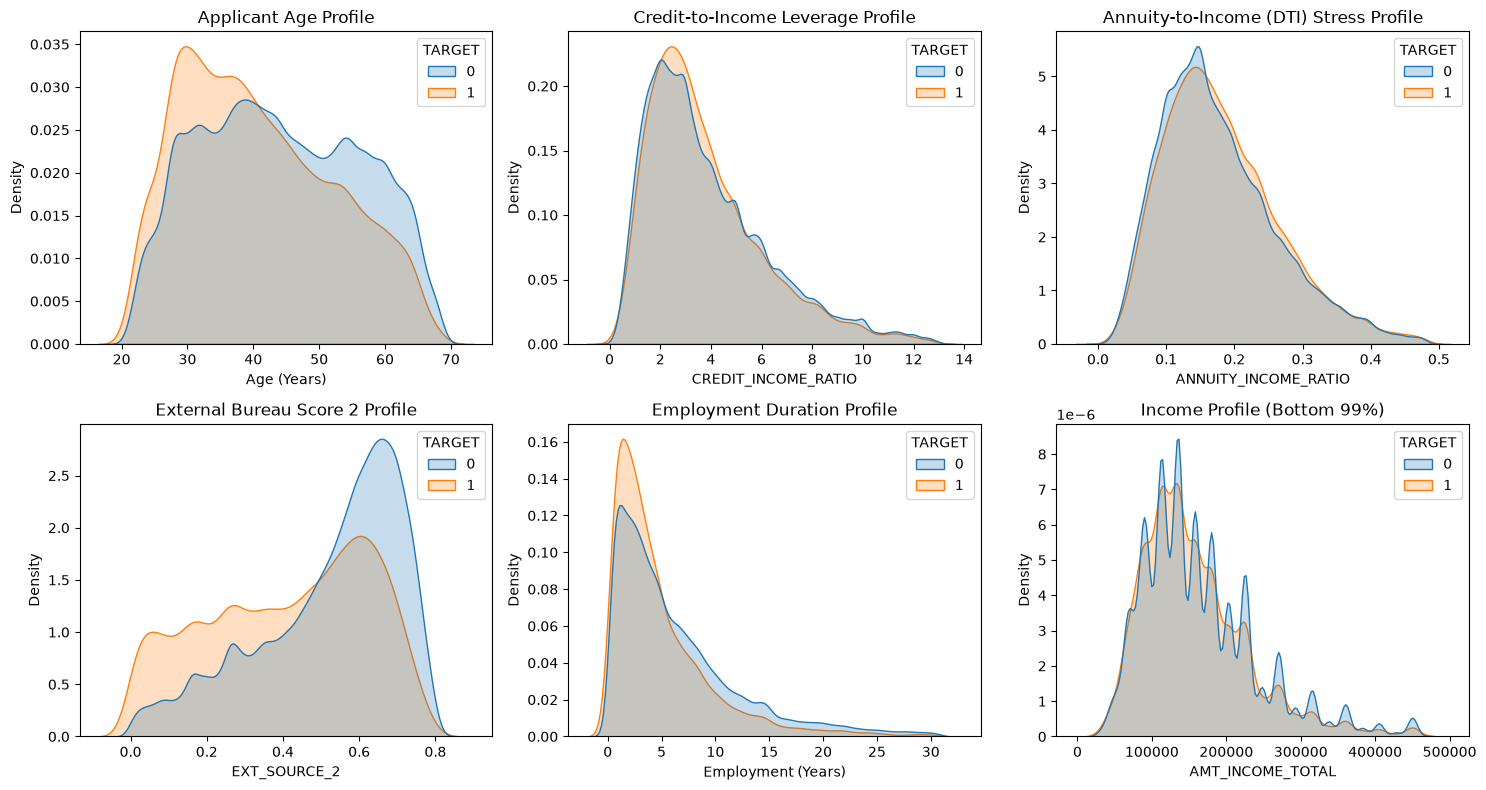

In [45]:
# plotting feature distributions using normalized density curves to look at risk profiles
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

# 1. applicant age
sns.kdeplot(data=application_features, x="AGE_YEARS", hue="TARGET", common_norm=False, fill=True, ax=ax[0, 0])
ax[0, 0].set_title("Applicant Age Profile")
ax[0, 0].set_xlabel("Age (Years)")

# 2. credit-to-income ratio (capped at 99th percentile for scale visibility)
q_credit = application_features["CREDIT_INCOME_RATIO"].quantile(0.99)
sns.kdeplot(data=application_features[application_features["CREDIT_INCOME_RATIO"] <= q_credit], 
            x="CREDIT_INCOME_RATIO", hue="TARGET", common_norm=False, fill=True, ax=ax[0, 1])
ax[0, 1].set_title("Credit-to-Income Leverage Profile")

# 3. annuity-to-income ratio (capped at 99th percentile)
q_annuity = application_features["ANNUITY_INCOME_RATIO"].quantile(0.99)
sns.kdeplot(data=application_features[application_features["ANNUITY_INCOME_RATIO"] <= q_annuity], 
            x="ANNUITY_INCOME_RATIO", hue="TARGET", common_norm=False, fill=True, ax=ax[0, 2])
ax[0, 2].set_title("Annuity-to-Income (DTI) Stress Profile")

# 4. external score 2
sns.kdeplot(data=application_features, x="EXT_SOURCE_2", hue="TARGET", common_norm=False, fill=True, ax=ax[1, 0])
ax[1, 0].set_title("External Bureau Score 2 Profile")

# 5. employment duration (capped at 99th percentile)
q_emp = application_features["EMPLOYMENT_YEARS"].quantile(0.99)
sns.kdeplot(data=application_features[application_features["EMPLOYMENT_YEARS"] <= q_emp], 
            x="EMPLOYMENT_YEARS", hue="TARGET", common_norm=False, fill=True, ax=ax[1, 1])
ax[1, 1].set_title("Employment Duration Profile")
ax[1, 1].set_xlabel("Employment (Years)")

# 6. income distribution (capped at 99th percentile)
q_income = application_features["AMT_INCOME_TOTAL"].quantile(0.99)
sns.kdeplot(data=application_features[application_features["AMT_INCOME_TOTAL"] <= q_income], 
            x="AMT_INCOME_TOTAL", hue="TARGET", common_norm=False, fill=True, ax=ax[1, 2])
ax[1, 2].set_title("Income Profile")
ax[1, 2].ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()


## Historical Credit and Repayment Data

The application table describes the current applicants, but the dataset also contains several other tables which include historical information about previous borrowing and repayments from existing customers.

For the initial prototype I use three additional sources:
* **Bureau:** previous credit history with other lenders
* **Previous applications:** previous applications within the company
* **Instalments:** previous scheduled and actual payments

These tables contain multiple records per applicant, so we cannot join them directly without altering the structure of our current table. To resolve this problem, the data from those tables is aggregated to each unique applicant using a `.groupby("SK_ID_CURR").agg()` before joining them to our main data table. 

The grouping collapses the historical features down into clean summary counts and averages. I deliberately keep these aggregates simple and interpretable to evaluate model families across a shared baseline, rather than attempting extensive competition-style feature engineering such as deep feature synthesis, which would be a natural extension to this process.


In [47]:
historical_summary = pd.DataFrame({
    "Table": [
        "Bureau",
        "Previous applications",
        "Instalments"
    ],
    "Rows": [
        len(bureau),
        len(previous_application),
        len(installments)
    ],
    "Applicants": [
        bureau["SK_ID_CURR"].nunique(),
        previous_application["SK_ID_CURR"].nunique(),
        installments["SK_ID_CURR"].nunique()
    ]
})

display(historical_summary)

,Table,Rows,Applicants
0,Bureau,1716428,305811
1,Previous applications,1670214,338857
2,Instalments,13605401,339587


### Bureau History

The bureau data contains an applicant's previous credit history with other lenders.

For the initial model, I summarise this history using a small number of intuitive features describing the number and size of previous credits, outstanding debt, overdue amounts and the age of the credit history.

These applicant-level summaries are then joined to the current application using `SK_ID_CURR`.

In [50]:
bureau_features = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_CREDIT_COUNT=("SK_ID_BUREAU", "count"),
    BUREAU_TOTAL_CREDIT=("AMT_CREDIT_SUM", "sum"),
    BUREAU_AVG_CREDIT=("AMT_CREDIT_SUM", "mean"),
    BUREAU_TOTAL_DEBT=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_MAX_OVERDUE=("AMT_CREDIT_MAX_OVERDUE", "max"),
    BUREAU_AVG_DAYS_CREDIT=("DAYS_CREDIT", "mean")
).reset_index()

display(bureau_features.head())


,SK_ID_CURR,BUREAU_CREDIT_COUNT,BUREAU_TOTAL_CREDIT,BUREAU_AVG_CREDIT,BUREAU_TOTAL_DEBT,BUREAU_MAX_OVERDUE,BUREAU_AVG_DAYS_CREDIT
0,100001,7,1453365.000,207623.571429,596686.5,NaN,-735.000000
1,100002,8,865055.565,108131.945625,245781.0,5043.645,-874.000000
2,100003,4,1017400.500,254350.125000,0.0,0.000,-1400.750000
3,100004,2,189037.800,94518.900000,0.0,0.000,-867.000000
4,100005,3,657126.000,219042.000000,568408.5,0.000,-190.666667


### Previous Applications

I summarise previous Home Credit applications using the number of applications and simple statistics describing previous credit, annuity and goods values.


In [51]:
previous_features = previous_application.groupby("SK_ID_CURR").agg(PREVIOUS_APPLICATION_COUNT=("SK_ID_PREV", "count"),
                                                                   PREVIOUS_AVG_CREDIT=("AMT_CREDIT", "mean"),
                                                                   PREVIOUS_MAX_CREDIT=("AMT_CREDIT", "max"),
                                                                   PREVIOUS_AVG_ANNUITY=("AMT_ANNUITY", "mean"),
                                                                   PREVIOUS_AVG_GOODS_PRICE=("AMT_GOODS_PRICE", "mean")).reset_index()

display(previous_features.head())

,SK_ID_CURR,PREVIOUS_APPLICATION_COUNT,PREVIOUS_AVG_CREDIT,PREVIOUS_MAX_CREDIT,PREVIOUS_AVG_ANNUITY,PREVIOUS_AVG_GOODS_PRICE
0,100001,1,23787.00,23787.0,3951.000,24835.5
1,100002,1,179055.00,179055.0,9251.775,179055.0
2,100003,3,484191.00,1035882.0,56553.990,435436.5
3,100004,1,20106.00,20106.0,5357.250,24282.0
4,100005,2,20076.75,40153.5,4813.200,44617.5


### Instalment History

Previous instalment records provide a simple view of repayment history. For this prototype I use the number of records and the average and maximum scheduled and actual payments.

In [52]:
installment_features = installments.groupby("SK_ID_CURR").agg(INSTALLMENT_RECORD_COUNT=("SK_ID_PREV", "count"),
                                                              AVG_INSTALLMENT=("AMT_INSTALMENT", "mean"),
                                                              MAX_INSTALLMENT=("AMT_INSTALMENT", "max"),
                                                              AVG_ACTUAL_PAYMENT=("AMT_PAYMENT", "mean"),
                                                              MAX_ACTUAL_PAYMENT=("AMT_PAYMENT", "max")).reset_index()

display(installment_features.head())

,SK_ID_CURR,INSTALLMENT_RECORD_COUNT,AVG_INSTALLMENT,MAX_INSTALLMENT,AVG_ACTUAL_PAYMENT,MAX_ACTUAL_PAYMENT
0,100001,7,5885.132143,17397.900,5885.132143,17397.900
1,100002,19,11559.247105,53093.745,11559.247105,53093.745
2,100003,25,64754.586000,560835.360,64754.586000,560835.360
3,100004,3,7096.155000,10573.965,7096.155000,10573.965
4,100005,9,6240.205000,17656.245,6240.205000,17656.245


## Final Modelling Dataset

The exploratory work above informed the reusable feature-engineering pipeline implemented in `src/data_engineering.py`.

I now run that pipeline to create the common modelling population that will be used by all three model families:

1. Logistic Regression
2. LightGBM
3. Neural Network

Keeping the underlying features and hold-out population consistent makes the model comparison easier to interpret.

In [55]:
df = build_dataset(application_train,bureau,previous_application,installments)

X_train, X_test, y_train, y_test, id_train, id_test = prepare_train_test(df)


Train: (246008, 144) | Test: (61503, 144)
Train default rate: 0.0807 | Test default rate: 0.0807
Missing indicators: 44


##  Conclusions

Looking at the raw data leads to a few clear choices for our modeling setup:

1. **Class imbalance:** The default rate is only around 8%. Because standard accuracy is misleading when the data is this skewed, we will use ranking and probability metrics like **ROC-AUC** to evaluate if the models are any good at separating risk.

2. **Missing data:** A lot of columns have massive gaps. To handle this for our prototype, our script sets a simple 50% cutoff rule to drop heavily missing columns. For the columns we keep, we dynamically build binary missingness flags to capture any hidden signal, and we calculate imputation values using the training split only to prevent data leakage.

3. **Data quality:** Aside from the `DAYS_EMPLOYED` column has a massive outlier at `365243` which represents an impossible 1,000 years of work. Our script replaces this placeholder error with `NaN` before we convert the negative day values into clean, positive years. Otherwise the data in general was of good quality

4. **Feature engineering:** Instead of building hundreds of complex variables, I chose a small set of interpretable affordability ratios (like Debt-to-Income and Loan-to-Value proxies) alongside simple summary counts and averages from the historical tables.

5. **Individual predictors:** The density plots show that the good and default distributions heavily overlap across almost every single feature on its own. This confirms that a single variable cannot predict default, so the modeling stage will test whether combining these partial signals creates a stronger risk differentiator.

6. **Controlled comparison:** To make the experiment completely honest, our Logistic Regression baseline, LightGBM challenger, and PyTorch Neural Network will train and validate on the exact same dataset splits. Any model-specific tweaks—like One-Hot Encoding for linear weights versus Ordinal Encoding for the trees—will be handled separately inside their own utility files.
